# v6 — **Predictive research laboratory**
**US · Eurozone · UK · Switzerland · Japan** — a structured engine for evaluating competing explanations of relative equity returns

## Why the approach changes here
v1–v5 followed a manual loop: hypothesise → build one signal → test → reject → hypothesise again. That loop produced real knowledge (documented below) but it does not scale and it tempts us to keep proposing combinations until one survives by chance.
v6 replaces it with a **research engine**: one feature matrix, one validation protocol, a small model tournament, and systematic feature attribution.

**This is explicitly not a search for the model that looks best historically.** It is built to answer:
which variables carry information · which are redundant · which relationships are linear vs nonlinear · which combinations add incrementally · which relationships are stable across countries and periods.

## Knowledge carried forward from v1–v5 (priors, not re-tested from scratch)
| Finding | Consequence for v6 |
|---|---|
| PMI has wrong-sign / no predictive relationship | included, but not privileged |
| FCI carries some information | included |
| EPS revision 6M > 3M > 1M; EPS *growth* adds nothing after revisions | both included so the engine can confirm or deny |
| Valuation predicts the **multiple leg** (+0.149/+0.097) but the **earnings leg** cancels it | component targets are first-class citizens here |
| GARP (cheap × earnings *momentum*) rejected | the new interaction is cheap × earnings **stability** |
| Oil betas near-identical across markets | oil enters only in local-currency form |
| 25,301-combination sweep: 6 cleared family-wise significance, 0 survived validation | **every result in v6 is measured against a null ceiling** |
| US supplied +157% of L/S P&L | country attribution is mandatory on every claim |

## The binding statistical constraint
| Quantity | Value |
|---|---|
| Country-month rows | 1,225 |
| Relative returns sum to zero each month → df per month | **4, not 5** |
| First principal component of the 5 return series | **78 %** of variance |
| Independent non-overlapping 6M windows | 40 (≈30 after the valuation warm-up) |

~21 predictors against ~30 independent observations. **Model *ranking* cannot be established at this sample size; feature *attribution* and *redundancy* can.**
The tournament is therefore reported as a diagnostic, never as "the winning model", and the whole pipeline is benchmarked against a shuffled-label null.

## Protocol (fixed before any v6 result)
* **Target (primary):** relative USD total return over 3M and 6M, i.e. $Y_{i,t,h}=R_{i,t,h}-\overline{R}_{t,h}$. **Secondary:** the multiple, earnings and FX legs.
* **Features are cross-sectionally z-scored every month.** A globally common variable (VIX, Brent, DXY) z-scores to exactly zero and drops out by construction — which is the correct treatment for a *relative* model.
* **Validation:** expanding-window walk-forward, refit annually, **6-month purge** between the last training label and the prediction date. No month is ever predicted by a model that saw its outcome.
* **Null ceiling:** the entire pipeline — all models, all walk-forward folds — is re-run on block-shuffled country labels. A model only counts if it beats what the *best* model achieves on noise.
* **Models:** Ridge · Elastic Net · additive-spline GAM · shallow gradient boosting (depth 2) · plus a one-feature benchmark (EPS revision 6M).
* **Mandatory on every claim:** country attribution · non-overlapping 6M check · stability across sub-periods.
* **Scope:** this is the *relative allocation* model (Model B). A global-regime model (Model A) is included only as a short appendix diagnostic — with ~30 independent windows an absolute-timing forecast cannot be validated, and the brief asks only for a relative ranking.

## 0. Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time, warnings
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.preprocessing import SplineTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')

pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 230
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); RAW, DATA = ROOT/'data'/'raw', ROOT/'data'
OUT = ROOT/'output'/'v6'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)

COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
H_PRIMARY, PURGE, MIN_TRAIN, REFIT_EVERY = 3, 6, 72, 12
N_NULL, SEED = 120, 7
LEDGER = []
def log(eid, question, verdict, evidence=''): LEDGER.append(dict(id=eid, question=question, verdict=verdict, evidence=evidence))

SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', fci=('GSFCI Index', -1),   y2='USGGT02Y Index', oas='LF98OAS Index',  pmi='NAPMPMI Index',  fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    fci=('BFCIEU Index', +1),  y2='GDBR2 Index',    oas='LECPOAS Index', pmi='MPMIEZMA Index', fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    fci=('GSGBFCI Index', -1), y2='GUKG2 Index',    oas='LC61OAS Index', pmi='MPMIGBMA Index', fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    fci=('GSEAFCI Index', -1), y2='GSWISS02 Index', oas='LECPOAS Index', pmi='CH_PMI',         fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    fci=('GSJPFCI Index', -1), y2='GJGB2 Index',    oas='LJC1OAS Index', pmi='JPYPMI',         fx=('USDJPY BGN Curncy', 'invert')),
}
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
def load(s):
    d = monthly(pd.read_excel(RAW/s['file']))
    o = pd.DataFrame({'pe': d['BEst P/E Ratio'], 'eps': d[s['eps']], 'y2': d[s['y2']], 'oas': d[s['oas']], 'pmi': d[s['pmi']]})
    o['fci'] = s['fci'][1] * d[s['fci'][0]]
    o['fx'] = 1.0 if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return o
fr = {c: load(SPEC[c]) for c in COUNTRIES}
IDX = pd.period_range(max(fr[c].pe.first_valid_index() for c in COUNTRIES), min(fr[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, Y2, OAS, PMI, FCI, FX = [pd.DataFrame({c: fr[c][k] for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'y2', 'oas', 'pmi', 'fci', 'fx')]
us = monthly(pd.read_excel(RAW/'US_raw_data.xlsx')); VIX, OIL, DXY = (us[k].reindex(IDX) for k in ('VIX Index', 'CO1 Comdty', 'DXY Index'))
AS_OF = IDX[-1]; PX = PE * EPS; PX_USD = PX * FX; R_USD = PX_USD.pct_change()
print(f'Panel {IDX[0]} -> {AS_OF}: {len(IDX)} months x 5 markets = {len(IDX)*5} rows.')
print('Price = fwd P/E x fwd EPS (identity; verified against the real index in v4 §12b). Price return only - no dividends.')

Panel 2005-12 -> 2026-04: 245 months x 5 markets = 1225 rows.
Price = fwd P/E x fwd EPS (identity; verified against the real index in v4 §12b). Price return only - no dividends.


## 1. Feature matrix
16 country-specific features across the four pillars plus two external, and 5 pre-defined economic interactions. **No feature is added later.**

| Pillar | Features |
|---|---|
| Macro | FCI 3M impulse · FCI 6M impulse · credit spread 6M tightening · PMI level · PMI 3M momentum · 2Y yield 6M fall |
| Micro | EPS revision 3M · EPS revision 6M · **EPS revision stability** (inverse volatility of monthly EPS changes, 12M) |
| Valuation | P/E vs own history · P/E vs peers · earnings yield − 2Y yield |
| Technical | momentum 6-1M · momentum 12-1M |
| External | FX momentum 6M · local-currency oil cost 6M (inverted) |

| Interaction | Economic question |
|---|---|
| cheap × EPS stability | does cheapness pay when estimates are *not* being cut? *(the Phase-1 output)* |
| cheap × FCI easing | do attractive valuations need easier financing to re-rate? |
| 2Y fall × credit tightening | monetary easing vs growth stress |
| FCI easing × EPS revisions | do supportive conditions amplify earnings upgrades? |
| momentum × EPS revisions | is trend stronger when earnings confirm it? |

In [2]:
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
z_own = lambda x, w=60: (x - x.expanding(w).mean()) / x.expanding(w).std()
own_sd = lambda d, w=36: d / d.expanding(w).std()
PM = PMI.shift(1)
eps_chg = EPS.pct_change()
RAW_F = {
 'macro_fci_3m':      own_sd(FCI - FCI.shift(3)),
 'macro_fci_6m':      own_sd(FCI - FCI.shift(6)),
 'macro_credit_6m':  -own_sd(OAS - OAS.shift(6)),
 'macro_pmi_level':   PM,
 'macro_pmi_3m':      PM - PM.shift(3),
 'macro_2y_fall_6m': -own_sd(Y2 - Y2.shift(6)),
 'micro_eps_rev_3m':  EPS / EPS.shift(3) - 1,
 'micro_eps_rev_6m':  EPS / EPS.shift(6) - 1,
 'micro_eps_stab':   -eps_chg.rolling(12).std(),
 'val_pe_own':       -z_own(PE),
 'val_pe_peers':     -z_own(PE.div(PE.mean(axis=1), axis=0)),
 'val_erp':           z_own(100 / PE - Y2),
 'tech_mom_6_1':      PX.shift(1) / PX.shift(7) - 1,
 'tech_mom_12_1':     PX.shift(1) / PX.shift(13) - 1,
 'ext_fx_mom_6m':     FX / FX.shift(6) - 1,
 'ext_oil_local_6m': -(pd.DataFrame({c: OIL / FX[c] for c in COUNTRIES}).pipe(lambda d: d / d.shift(6) - 1)),
}
Z = {k: cs_z(v.reindex(IDX)) for k, v in RAW_F.items()}
INTER = {
 'ix_cheap_x_epsstab': Z['val_pe_peers'] * Z['micro_eps_stab'],
 'ix_cheap_x_fci':     Z['val_pe_peers'] * Z['macro_fci_6m'],
 'ix_2y_x_credit':     Z['macro_2y_fall_6m'] * Z['macro_credit_6m'],
 'ix_fci_x_epsrev':    Z['macro_fci_6m'] * Z['micro_eps_rev_6m'],
 'ix_mom_x_epsrev':    Z['tech_mom_12_1'] * Z['micro_eps_rev_6m'],
}
Z.update({k: cs_z(v) for k, v in INTER.items()})
FEATS = list(Z); BASE_FEATS = [f for f in FEATS if not f.startswith('ix_')]
print(f'{len(BASE_FEATS)} base features + {len(INTER)} interactions = {len(FEATS)} predictors')
for g in ('macro', 'micro', 'val', 'tech', 'ext', 'ix'):
    print(f'  {g:6s}: {[f for f in FEATS if f.startswith(g)]}')
print('\nNote: VIX, Brent and DXY are identical across markets, so cross-sectional z-scoring sends them to exactly 0.')
print('They cannot enter a RELATIVE model as raw features - only through country-specific forms (local-currency oil) or as regime conditioners (appendix).')

# targets
TGT = {}
for h in (3, 6):
    tot = PX_USD.shift(-h) / PX_USD - 1
    TGT[('total_usd', h)] = tot.sub(tot.mean(axis=1), axis=0)
    TGT[('multiple', h)] = np.log(PE.shift(-h) / PE).pipe(lambda d: d.sub(d.mean(axis=1), axis=0))
    TGT[('earnings', h)] = np.log(EPS.shift(-h) / EPS).pipe(lambda d: d.sub(d.mean(axis=1), axis=0))
    TGT[('fx', h)] = np.log(FX.shift(-h) / FX).pipe(lambda d: d.sub(d.mean(axis=1), axis=0))
VALID = pd.Series({t: all(Z[f].loc[t].notna().all() for f in FEATS) for t in IDX})
FIRST = VALID[VALID].index.min()
print(f'\nAll {len(FEATS)} predictors valid from {FIRST} ({int(VALID.sum())} usable months).')

16 base features + 5 interactions = 21 predictors
  macro : ['macro_fci_3m', 'macro_fci_6m', 'macro_credit_6m', 'macro_pmi_level', 'macro_pmi_3m', 'macro_2y_fall_6m']
  micro : ['micro_eps_rev_3m', 'micro_eps_rev_6m', 'micro_eps_stab']
  val   : ['val_pe_own', 'val_pe_peers', 'val_erp']
  tech  : ['tech_mom_6_1', 'tech_mom_12_1']
  ext   : ['ext_fx_mom_6m', 'ext_oil_local_6m']
  ix    : ['ix_cheap_x_epsstab', 'ix_cheap_x_fci', 'ix_2y_x_credit', 'ix_fci_x_epsrev', 'ix_mom_x_epsrev']

Note: VIX, Brent and DXY are identical across markets, so cross-sectional z-scoring sends them to exactly 0.
They cannot enter a RELATIVE model as raw features - only through country-specific forms (local-currency oil) or as regime conditioners (appendix).



All 21 predictors valid from 2010-11 (186 usable months).


## 2. (A) Univariate evaluation
Every predictor on its own, against the primary target and the three return legs. Nothing is selected here — this is the evidence base.

In [3]:
def ic_series(sig, tgt):
    o = {}
    for t in sig.index:
        a, b = sig.loc[t], tgt.loc[t]
        if a.notna().all() and b.notna().all() and a.nunique() > 1: o[t] = spearmanr(a, b).statistic
    return pd.Series(o)
def nw_t(x, lags=3):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return float(sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0]) if len(x) > 12 else np.nan
HALF = IDX[(len(IDX) + list(IDX).index(FIRST)) // 2]
rows = []
for f in FEATS:
    ic3 = ic_series(Z[f], TGT[('total_usd', 3)]); ic6 = ic_series(Z[f], TGT[('total_usd', 6)])
    r = {'feature': f, 'IC 3M': ic3.mean(), 't 3M': nw_t(ic3.values), 'IC 6M': ic6.mean(), 't 6M': nw_t(ic6.values, 6)}
    for leg in ('multiple', 'earnings', 'fx'):
        r[f'IC {leg}'] = ic_series(Z[f], TGT[(leg, 3)]).mean()
    r['IC 1st half'] = ic3[ic3.index <= HALF].mean(); r['IC 2nd half'] = ic3[ic3.index > HALF].mean()
    r['sign stable'] = (r['IC 1st half'] > 0) == (r['IC 2nd half'] > 0) and r['IC 3M'] > 0
    rows.append(r)
UNI = pd.DataFrame(rows).set_index('feature').sort_values('IC 3M', ascending=False)
display(UNI.style.format({c: '{:+.3f}' for c in UNI.columns if c.startswith('IC')} | {c: '{:+.2f}' for c in UNI.columns if c.startswith('t ')}))
print('Sign-stable and positive on the primary target:', [f for f in UNI.index if UNI.loc[f, 'sign stable']])

,IC 3M,t 3M,IC 6M,t 6M,IC multiple,IC earnings,IC fx,IC 1st half,IC 2nd half,sign stable
feature,,,,,,,,,,
micro_eps_rev_6m,+0.131,+2.60,+0.130,+1.92,-0.089,+0.333,-0.030,+0.151,+0.098,True
micro_eps_stab,+0.108,+2.50,+0.126,+2.27,+0.103,+0.046,-0.073,+0.070,+0.170,True
macro_fci_6m,+0.101,+2.00,+0.174,+2.96,-0.069,+0.213,+0.035,+0.060,+0.154,True
macro_fci_3m,+0.074,+1.62,+0.108,+2.38,-0.097,+0.183,+0.034,+0.063,+0.089,True
tech_mom_12_1,+0.071,+1.60,+0.086,+1.57,-0.080,+0.234,-0.024,+0.067,+0.078,True
micro_eps_rev_3m,+0.048,+1.08,+0.084,+1.53,-0.215,+0.376,-0.028,+0.029,+0.080,True
ix_mom_x_epsrev,+0.047,+1.21,+0.050,+0.98,+0.029,+0.025,+0.059,+0.069,+0.013,True
ix_2y_x_credit,+0.047,+1.15,+0.069,+1.34,-0.004,+0.026,+0.047,-0.001,+0.107,False
macro_pmi_level,+0.042,+0.94,+0.060,+1.06,+0.002,+0.016,+0.043,+0.002,+0.109,True


Sign-stable and positive on the primary target: ['micro_eps_rev_6m', 'micro_eps_stab', 'macro_fci_6m', 'macro_fci_3m', 'tech_mom_12_1', 'micro_eps_rev_3m', 'ix_mom_x_epsrev', 'macro_pmi_level', 'ix_fci_x_epsrev']


### Redundancy structure
Which predictors carry the same information? Correlated features make any single-model importance ranking unstable, so this is read before the tournament, not after.

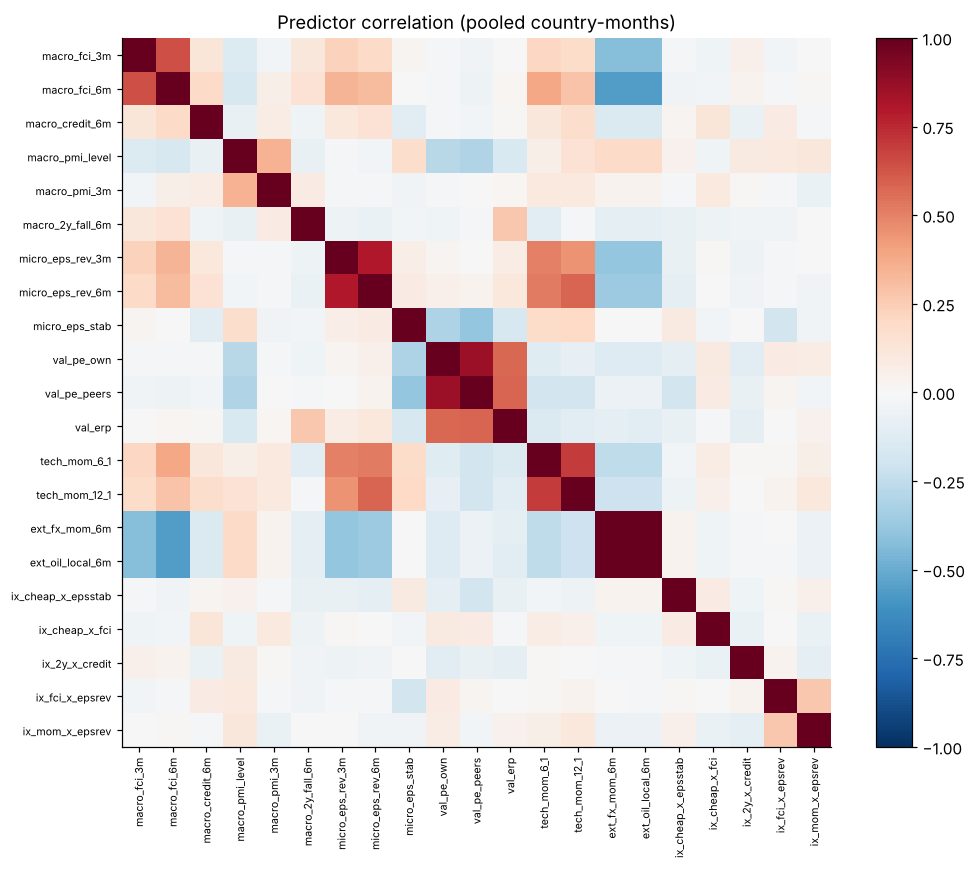

Pairs with |r| > 0.6: 5
   +1.00  ext_fx_mom_6m ~ ext_oil_local_6m
   +0.86  val_pe_own ~ val_pe_peers
   +0.80  micro_eps_rev_3m ~ micro_eps_rev_6m
   +0.70  tech_mom_6_1 ~ tech_mom_12_1
   +0.64  macro_fci_3m ~ macro_fci_6m
Effective dimensionality: 14 components explain 90% of the variance of 21 predictors.


In [4]:
POOL = pd.DataFrame({f: pd.concat([Z[f][c] for c in COUNTRIES]).reset_index(drop=True) for f in FEATS}).dropna()
CORR = POOL.corr()
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(CORR.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATS))); ax.set_xticklabels(FEATS, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATS))); ax.set_yticklabels(FEATS, fontsize=7); ax.grid(False)
plt.colorbar(im, fraction=0.046); ax.set_title('Predictor correlation (pooled country-months)')
plt.tight_layout(); plt.savefig(CH/'fig_v6_corr.png', dpi=200, bbox_inches='tight'); plt.show()
iu = np.triu_indices(len(FEATS), 1); pairs = [(FEATS[i], FEATS[j], CORR.values[i, j]) for i, j in zip(*iu) if abs(CORR.values[i, j]) > 0.6]
print(f'Pairs with |r| > 0.6: {len(pairs)}')
for a, b, r in sorted(pairs, key=lambda x: -abs(x[2]))[:10]: print(f'   {r:+.2f}  {a} ~ {b}')
ev = np.linalg.eigvalsh(CORR.values)[::-1]
print(f'Effective dimensionality: {int((ev.cumsum()/ev.sum() < 0.9).sum())+1} components explain 90% of the variance of {len(FEATS)} predictors.')

## 3. The walk-forward engine
Expanding window · refit annually · **6-month purge** so no training label overlaps the prediction month · features standardised on training data only.

In [5]:
def panel(months, feats):
    X = np.stack([np.stack([Z[f].loc[t].to_numpy(float) for f in feats], axis=1) for t in months])   # (T,5,p)
    return X.reshape(-1, len(feats))
def targ(months, key):
    return np.concatenate([TGT[key].loc[t].to_numpy(float) for t in months])

def make_models(seed=0):
    return {
     'Ridge':        make_pipeline(Ridge(alpha=50.0)),
     'ElasticNet':   make_pipeline(ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000)),   # alpha calibrated to the target scale (sd 0.035): 0.02 zeroes every coefficient
     'GAM (splines)': make_pipeline(SplineTransformer(n_knots=4, degree=3, include_bias=False), Ridge(alpha=200.0)),
     'Boosting (d2)': HistGradientBoostingRegressor(max_depth=2, max_iter=120, learning_rate=0.05,
                                                     min_samples_leaf=40, l2_regularization=1.0, random_state=seed),
    }

def walk_forward(feats, key=('total_usd', H_PRIMARY), Zsrc=None, models=None, return_preds=False):
    """expanding window, annual refit, PURGE months between last training label and prediction"""
    global Z
    saved = Z
    if Zsrc is not None: Z = Zsrc
    try:
        months = [t for t in IDX if VALID[t] and not np.isnan(TGT[key].loc[t]).any()]
        months = [t for t in months if t >= FIRST]
        preds = {}; fitted = None; last_fit = -10**9
        for i, t in enumerate(months):
            if i < MIN_TRAIN: continue
            if i - last_fit >= REFIT_EVERY or fitted is None:
                tr = months[:max(0, i - PURGE)]
                if len(tr) < MIN_TRAIN: continue
                Xtr, ytr = panel(tr, feats), targ(tr, key)
                ok = ~np.isnan(Xtr).any(1) & ~np.isnan(ytr)
                Xtr, ytr = Xtr[ok], ytr[ok]
                mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1
                fitted = {}
                for nm, m in (models or make_models()).items():
                    try: fitted[nm] = m.fit((Xtr - mu) / sd, ytr)
                    except Exception: fitted[nm] = None
                last_fit = i; scaler = (mu, sd)
            Xte = panel([t], feats); Xte = (Xte - scaler[0]) / scaler[1]
            if np.isnan(Xte).any(): continue
            preds[t] = {nm: (m.predict(Xte) if m is not None else np.full(5, np.nan)) for nm, m in fitted.items()}
        out = {}
        for nm in (models or make_models()):
            P = pd.DataFrame({t: v[nm] for t, v in preds.items()}, index=COUNTRIES).T
            out[nm] = P
        return out
    finally:
        Z = saved

def score(P, key=('total_usd', H_PRIMARY)):
    ic = ic_series(P, TGT[key]); return ic
t0 = time.time(); PRED = walk_forward(FEATS); print(f'walk-forward (all {len(FEATS)} predictors) in {time.time()-t0:.0f}s')
oos_months = PRED['Ridge'].index
print(f'Out-of-sample months: {len(oos_months)}  ({oos_months.min()} -> {oos_months.max()})')

walk-forward (all 21 predictors) in 3s
Out-of-sample months: 105  (2017-05 -> 2026-01)


## 4. The model tournament — and the null ceiling underneath it
Each model's out-of-sample rank IC, plus a one-feature benchmark. **Then the identical pipeline is re-run on block-shuffled country labels**, so we can see what the *best of four models* achieves when there is nothing to find.

In [6]:
bench_ic = ic_series(Z['micro_eps_rev_6m'].loc[oos_months], TGT[('total_usd', H_PRIMARY)])
rows = [{'model': 'Benchmark: EPS revision 6M (1 feature)', 'OOS IC': bench_ic.mean(), 'NW t': nw_t(bench_ic.values), 'hit rate': (bench_ic > 0).mean()}]
for nm, P in PRED.items():
    ic = score(P); rows.append({'model': nm, 'OOS IC': ic.mean(), 'NW t': nw_t(ic.values), 'hit rate': (ic > 0).mean()})
TOUR = pd.DataFrame(rows).set_index('model')
display(TOUR.style.format({'OOS IC': '{:+.3f}', 'NW t': '{:+.2f}', 'hit rate': '{:.0%}'}))

,OOS IC,NW t,hit rate
model,,,
Benchmark: EPS revision 6M (1 feature),+0.137,+1.80,64%
Ridge,+0.132,+1.99,61%
ElasticNet,+0.150,+2.19,62%
GAM (splines),+0.168,+2.65,64%
Boosting (d2),+0.084,+1.50,58%


120 null runs of the FULL pipeline in 309s

Best observed model OOS IC : +0.168
Best-of-4 NULL OOS IC      : median +0.029, 95th pct +0.140, max +0.179
p(best-of-4 null >= observed) = 0.017


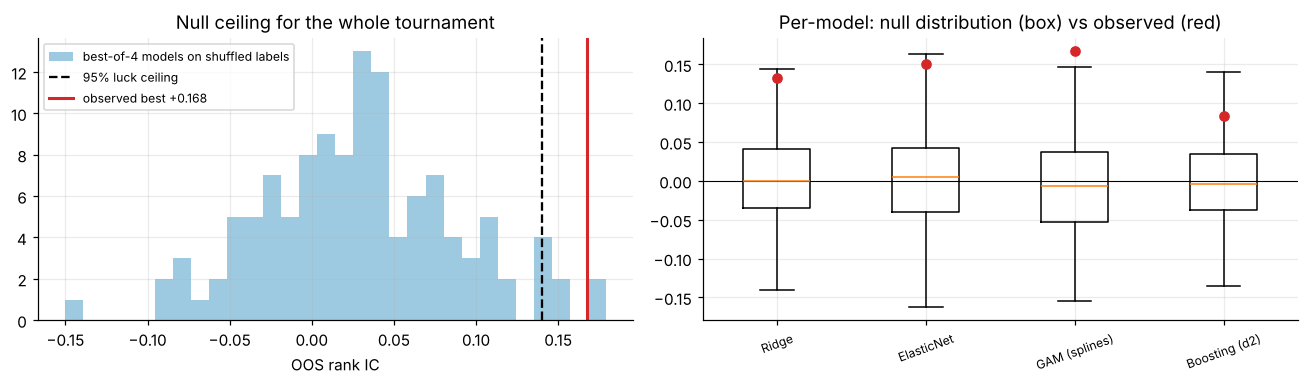

,OOS IC,NW t,hit rate,null median,p vs own null,p vs best-of-4 null
model,,,,,,
Benchmark: EPS revision 6M (1 feature),+0.137,+1.80,64%,+nan,nan,nan
Ridge,+0.132,+1.99,61%,+0.000,0.017,0.067
ElasticNet,+0.150,+2.19,62%,+0.005,0.017,0.025
GAM (splines),+0.168,+2.65,64%,-0.007,0.008,0.017
Boosting (d2),+0.084,+1.50,58%,-0.004,0.100,0.175


In [7]:
def shuffled_Z(seed, block=3):
    rng = np.random.default_rng(seed); T = len(IDX); blk = np.arange(T) // block
    perm = np.argsort(rng.random((blk.max() + 1, 5)), axis=1)[blk]      # same shuffle for every feature -> keeps cross-feature structure
    out = {}
    for f in FEATS:
        A = Z[f].to_numpy(float).copy()
        out[f] = pd.DataFrame(np.take_along_axis(A, perm, axis=1), index=IDX, columns=COUNTRIES)
    return out
t0 = time.time(); null_best, null_all = [], []
for s in range(N_NULL):
    Ps = walk_forward(FEATS, Zsrc=shuffled_Z(1000 + s))
    ics = {nm: score(P).mean() for nm, P in Ps.items()}
    null_all.append(ics); null_best.append(max(ics.values()))
null_best = np.array(null_best); NULLDF = pd.DataFrame(null_all)
print(f'{N_NULL} null runs of the FULL pipeline in {time.time()-t0:.0f}s')
obs_best = TOUR.drop(index='Benchmark: EPS revision 6M (1 feature)')['OOS IC'].max()
ceil95 = np.percentile(null_best, 95)
print(f'\nBest observed model OOS IC : {obs_best:+.3f}')
print(f'Best-of-4 NULL OOS IC      : median {np.median(null_best):+.3f}, 95th pct {ceil95:+.3f}, max {null_best.max():+.3f}')
print(f'p(best-of-4 null >= observed) = {(null_best >= obs_best).mean():.3f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(null_best, bins=30, color='#9ecae1', label='best-of-4 models on shuffled labels')
ax[0].axvline(ceil95, color='k', ls='--', label='95% luck ceiling'); ax[0].axvline(obs_best, color='#d62728', lw=2, label=f'observed best {obs_best:+.3f}')
ax[0].set_title('Null ceiling for the whole tournament'); ax[0].set_xlabel('OOS rank IC'); ax[0].legend(fontsize=8)
ax[1].boxplot([NULLDF[c].values for c in NULLDF.columns], tick_labels=list(NULLDF.columns), showfliers=False)
for i, c in enumerate(NULLDF.columns, start=1): ax[1].scatter([i], [TOUR.loc[c, 'OOS IC']], color='#d62728', zorder=5)
ax[1].axhline(0, color='k', lw=.7); ax[1].set_title('Per-model: null distribution (box) vs observed (red)'); ax[1].tick_params(axis='x', rotation=20, labelsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_v6_null_ceiling.png', dpi=200, bbox_inches='tight'); plt.show()
TOUR['null median'] = [np.nan] + [NULLDF[c].median() for c in NULLDF.columns]
TOUR['p vs own null'] = [np.nan] + [float((NULLDF[c] >= TOUR.loc[c, 'OOS IC']).mean()) for c in NULLDF.columns]
TOUR['p vs best-of-4 null'] = [np.nan] + [float((null_best >= TOUR.loc[c, 'OOS IC']).mean()) for c in NULLDF.columns]
display(TOUR.style.format({'OOS IC': '{:+.3f}', 'NW t': '{:+.2f}', 'hit rate': '{:.0%}', 'null median': '{:+.3f}', 'p vs own null': '{:.3f}', 'p vs best-of-4 null': '{:.3f}'}))
log('T0', 'Does any model beat the best-of-4 noise ceiling?', 'see table', f'observed best {obs_best:+.3f} vs 95% ceiling {ceil95:+.3f}')

## 5. (B) Incremental predictive power — nested feature groups
Add one pillar at a time to the engine and measure the change in out-of-sample IC. This answers "which column actually contributes" far more reliably than any importance score.

In [8]:
GROUPS = {'micro': [f for f in FEATS if f.startswith('micro')], 'macro': [f for f in FEATS if f.startswith('macro')],
          'val': [f for f in FEATS if f.startswith('val')], 'tech': [f for f in FEATS if f.startswith('tech')],
          'ext': [f for f in FEATS if f.startswith('ext')], 'ix': [f for f in FEATS if f.startswith('ix')]}
order = ['micro', 'macro', 'val', 'tech', 'ext', 'ix']
rows, cum = [], []
for g in order:
    cum = cum + GROUPS[g]
    P = walk_forward(cum)
    r = {'feature set': '+'.join(order[:order.index(g)+1]), 'n features': len(cum)}
    for nm, pr in P.items(): r[nm] = score(pr).mean()
    rows.append(r)
NEST = pd.DataFrame(rows).set_index('feature set')
display(NEST.style.format({c: '{:+.3f}' for c in NEST.columns if c != 'n features'}))

,n features,Ridge,ElasticNet,GAM (splines),Boosting (d2)
feature set,,,,,
micro,3,+0.176,+0.169,+0.115,+0.037
micro+macro,9,+0.117,+0.111,+0.110,+0.094
micro+macro+val,12,+0.103,+0.094,+0.055,+0.103
micro+macro+val+tech,14,+0.101,+0.099,+0.111,+0.116
micro+macro+val+tech+ext,16,+0.108,+0.102,+0.122,+0.094
micro+macro+val+tech+ext+ix,21,+0.132,+0.150,+0.168,+0.084


### Drop-one-group: what breaks if a pillar is removed?
The decisive attribution test — a feature group matters only if removing it *damages* out-of-sample prediction.

In [9]:
rows = []
for g in order:
    keep = [f for f in FEATS if not f.startswith(g)]
    P = walk_forward(keep)
    r = {'removed': g, 'n features': len(keep)}
    for nm, pr in P.items(): r[nm] = score(pr).mean() - TOUR.loc[nm, 'OOS IC']
    rows.append(r)
DROP = pd.DataFrame(rows).set_index('removed')
display(DROP.style.format({c: '{:+.3f}' for c in DROP.columns if c != 'n features'}).background_gradient(cmap='RdYlGn_r', subset=[c for c in DROP.columns if c != 'n features']))
print('Negative = removing the group HURT out-of-sample IC (the group was carrying information).')

,n features,Ridge,ElasticNet,GAM (splines),Boosting (d2)
removed,,,,,
micro,18,+0.005,-0.027,-0.059,-0.017
macro,15,-0.009,+0.005,-0.015,-0.064
val,18,+0.016,+0.006,+0.026,+0.024
tech,19,-0.013,-0.007,-0.017,+0.022
ext,19,+0.000,-0.001,-0.012,-0.016
ix,16,-0.025,-0.049,-0.046,+0.010


Negative = removing the group HURT out-of-sample IC (the group was carrying information).


## 6. (D) Feature attribution and stability
Three views, deliberately not one: standardised Ridge coefficients over time · Elastic Net selection frequency · out-of-sample permutation importance.
Correlated predictors make any single ranking unstable, so a feature is only credited when the views agree **and** the drop-one test above confirms it.

,Ridge coef (mean),Ridge coef (sign stable),ElasticNet selected %,OOS permutation importance,univariate IC 3M
macro_pmi_3m,-0.002,True,100%,+0.0170,-0.033
ix_cheap_x_epsstab,+0.002,True,100%,+0.0137,+0.023
micro_eps_stab,+0.005,True,100%,+0.0135,+0.108
micro_eps_rev_6m,+0.008,True,100%,+0.0127,+0.131
ix_fci_x_epsrev,+0.002,True,100%,+0.0117,+0.024
macro_credit_6m,-0.007,True,100%,+0.0117,-0.112
macro_fci_6m,+0.004,True,100%,+0.0113,+0.101
ix_mom_x_epsrev,+0.002,True,100%,+0.0106,+0.047
tech_mom_6_1,-0.001,True,67%,+0.0079,+0.023
ext_fx_mom_6m,-0.000,False,33%,+0.0073,-0.018


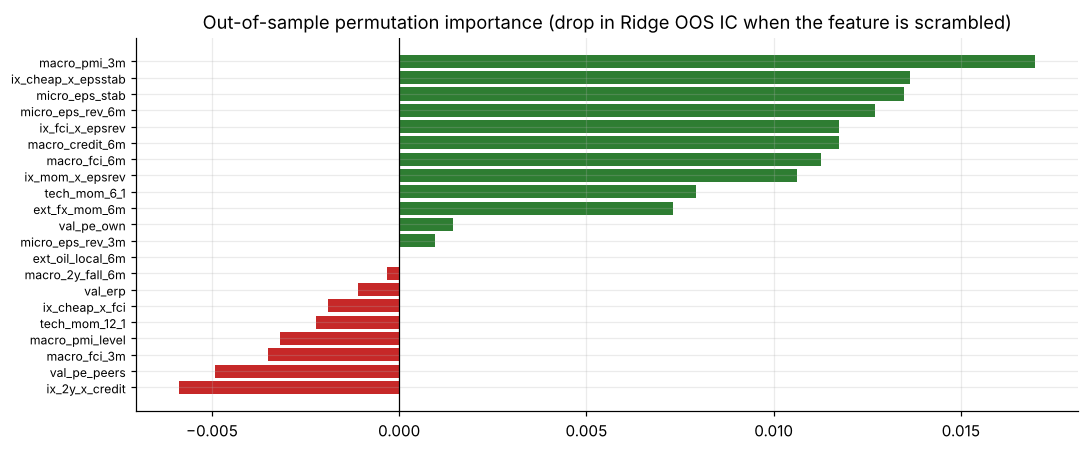

In [10]:
months = [t for t in IDX if VALID[t] and t >= FIRST and not np.isnan(TGT[('total_usd', H_PRIMARY)].loc[t]).any()]
coefs, enet_sel = {}, {}
for i in range(MIN_TRAIN, len(months), REFIT_EVERY):
    tr = months[:max(0, i - PURGE)]
    if len(tr) < MIN_TRAIN: continue
    X, y = panel(tr, FEATS), targ(tr, ('total_usd', H_PRIMARY))
    ok = ~np.isnan(X).any(1) & ~np.isnan(y); X, y = X[ok], y[ok]
    mu, sd = X.mean(0), X.std(0); sd[sd == 0] = 1; Xs = (X - mu) / sd
    coefs[months[i]] = pd.Series(Ridge(alpha=50.0).fit(Xs, y).coef_, index=FEATS)
    en = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000).fit(Xs, y)
    enet_sel[months[i]] = pd.Series(np.abs(en.coef_) > 1e-8, index=FEATS)
COEF = pd.DataFrame(coefs).T; SEL = pd.DataFrame(enet_sel).T
ATTR = pd.DataFrame({'Ridge coef (mean)': COEF.mean(), 'Ridge coef (sign stable)': (np.sign(COEF).abs().sum() == np.sign(COEF).sum().abs()),
                     'ElasticNet selected %': SEL.mean()})

rng = np.random.default_rng(SEED)
base_ic = TOUR.loc['Ridge', 'OOS IC']; perm_imp = {}
for f in FEATS:
    drops = []
    for rep in range(6):
        Zp = dict(Z); A = Z[f].to_numpy(float).copy()
        idx = np.argsort(rng.random(A.shape), axis=1)
        Zp[f] = pd.DataFrame(np.take_along_axis(A, idx, axis=1), index=IDX, columns=COUNTRIES)
        P = walk_forward(FEATS, Zsrc=Zp, models={'Ridge': make_pipeline(Ridge(alpha=50.0))})
        drops.append(base_ic - score(P['Ridge']).mean())
    perm_imp[f] = np.mean(drops)
ATTR['OOS permutation importance'] = pd.Series(perm_imp)
ATTR['univariate IC 3M'] = UNI['IC 3M']
ATTR = ATTR.sort_values('OOS permutation importance', ascending=False)
display(ATTR.style.format({'Ridge coef (mean)': '{:+.3f}', 'ElasticNet selected %': '{:.0%}', 'OOS permutation importance': '{:+.4f}', 'univariate IC 3M': '{:+.3f}'}))

fig, ax = plt.subplots(figsize=(10, 4.2))
ordf = ATTR.index
ax.barh(range(len(ordf)), ATTR['OOS permutation importance'].values, color=['#2e7d32' if v > 0 else '#c62828' for v in ATTR['OOS permutation importance']])
ax.set_yticks(range(len(ordf))); ax.set_yticklabels(ordf, fontsize=8); ax.invert_yaxis(); ax.axvline(0, color='k', lw=.8)
ax.set_title('Out-of-sample permutation importance (drop in Ridge OOS IC when the feature is scrambled)')
plt.tight_layout(); plt.savefig(CH/'fig_v6_attribution.png', dpi=200, bbox_inches='tight'); plt.show()

### Stability across sub-periods and countries

In [11]:
best_model = TOUR.drop(index='Benchmark: EPS revision 6M (1 feature)')['OOS IC'].idxmax()
Pb = PRED[best_model]; icb = score(Pb)
h = len(icb) // 2
sub = pd.DataFrame({'1st half': [icb.iloc[:h].mean(), nw_t(icb.iloc[:h].values)], '2nd half': [icb.iloc[h:].mean(), nw_t(icb.iloc[h:].values)]}, index=['IC', 'NW t'])
display(sub.style.format('{:+.3f}'))
def ls_w(s, H=3): return s.div(s.clip(lower=0).sum(axis=1), axis=0).rolling(H, min_periods=1).mean()
ctr = (ls_w(Pb).shift(1) * R_USD.reindex(Pb.index)).dropna(how='any')
display(pd.DataFrame({'mean monthly contribution (bps)': ctr.mean() * 1e4, 'avg weight': ls_w(Pb).mean(),
                      'months long': (ls_w(Pb) > 0).mean()}).style.format({'mean monthly contribution (bps)': '{:+.1f}', 'avg weight': '{:+.2f}', 'months long': '{:.0%}'}))
print('Reported in basis points, not as a share: the long/short total is near zero, which makes percentage shares meaningless.')
ic6 = ic_series(Pb, TGT[('total_usd', 6)]); nn = ic6.iloc[::6]
print(f'Non-overlapping 6M check: overlapping IC {ic6.mean():+.3f} (t {nw_t(ic6.values,6):+.2f}, n={len(ic6)}) | non-overlapping {nn.mean():+.3f} (t {nw_t(nn.values,0):+.2f}, n={len(nn)})')
pl = ctr.sum(axis=1); print(f'L/S USD Sharpe (OOS, 3M tranches, gross): {pl.mean()*12/(pl.std()*np.sqrt(12)):.2f}')

,1st half,2nd half
IC,+0.187,+0.149
NW t,+2.209,+1.611


,mean monthly contribution (bps),avg weight,months long
US,+43.5,+0.12,69%
Eurozone,-52.0,-0.02,45%
UK,-43.6,-0.32,20%
Switzerland,-1.3,+0.01,49%
Japan,+50.2,+0.19,68%


Reported in basis points, not as a share: the long/short total is near zero, which makes percentage shares meaningless.
Non-overlapping 6M check: overlapping IC +0.184 (t +2.02, n=102) | non-overlapping +0.306 (t +3.27, n=17)
L/S USD Sharpe (OOS, 3M tranches, gross): -0.03


### Why does a positive IC not become P&L?
The best model ranks the five markets better than chance yet the long/short book makes nothing. Rank correlation ignores *magnitudes*, so a model can be right about order and wrong about size.
Three diagnostics: average realised return by predicted rank · score-weighted vs equal-weighted construction · whether the IC is good in months when there is little to win.

In [12]:
rk = Pb.rank(axis=1, ascending=False)
fwd1 = R_USD.reindex(Pb.index).shift(-1)
byrank = pd.Series({int(k): float(fwd1.where(rk == k).stack().mean() * 1e4) for k in range(1, 6)})
display(byrank.to_frame('mean next-month return by predicted rank (bps)').style.format('{:+.0f}'))
ew = ((rk <= 2).astype(float) / 2 - (rk >= 4).astype(float) / 2)
r_ew = (ew.rolling(3, min_periods=1).mean().shift(1) * R_USD.reindex(Pb.index)).dropna(how='any').sum(axis=1)
r_sw = ctr.sum(axis=1)
shp = lambda x: x.mean() * 12 / (x.std() * np.sqrt(12))
print(f'Score-weighted L/S Sharpe {shp(r_sw):+.2f}   |   Equal-weighted top2-minus-bottom2 Sharpe {shp(r_ew):+.2f}')
disp = R_USD.reindex(Pb.index).shift(-1).std(axis=1)
j = pd.concat([icb.rename('ic'), disp.rename('dispersion')], axis=1).dropna()
lo, hi = j.dispersion.quantile([1/3, 2/3])
print(f'IC when cross-market dispersion is LOW {j[j.dispersion<=lo].ic.mean():+.3f} | MID {j[(j.dispersion>lo)&(j.dispersion<hi)].ic.mean():+.3f} | HIGH {j[j.dispersion>=hi].ic.mean():+.3f}')
print(f'corr(monthly IC, next-month dispersion) = {j.ic.corr(j.dispersion):+.2f}')
log('T1', 'Does the OOS IC convert into P&L?', 'NO',
    f'IC {icb.mean():+.3f} but score-weighted L/S Sharpe {shp(r_sw):+.2f}, equal-weighted {shp(r_ew):+.2f}')

,mean next-month return by predicted rank (bps)
1,+86
2,+71
3,+68
4,+74
5,+45


Score-weighted L/S Sharpe -0.03   |   Equal-weighted top2-minus-bottom2 Sharpe +0.51
IC when cross-market dispersion is LOW +0.154 | MID +0.188 | HIGH +0.151
corr(monthly IC, next-month dispersion) = -0.01


## 7. Verdict, scorecard and current ranking

In [13]:
ATTR['views agreeing'] = ((ATTR['OOS permutation importance'] > 0).astype(int) + (ATTR['ElasticNet selected %'] > 0.5).astype(int)
                          + (ATTR['univariate IC 3M'] > 0).astype(int) + ATTR['Ridge coef (sign stable)'].astype(int))
display(ATTR[['univariate IC 3M', 'Ridge coef (sign stable)', 'ElasticNet selected %', 'OOS permutation importance', 'views agreeing']]
        .sort_values('views agreeing', ascending=False).style.format({'univariate IC 3M': '{:+.3f}', 'ElasticNet selected %': '{:.0%}', 'OOS permutation importance': '{:+.4f}'}))
survivors = ATTR[ATTR['views agreeing'] == 4].index.tolist()
print('Features credited by ALL FOUR views (positive univariate IC, sign-stable Ridge coefficient, ElasticNet selection >50%, positive permutation importance):')
print('  ', survivors if survivors else 'NONE')
PILL = {'Macro': [f for f in survivors if f.startswith('macro')], 'Micro': [f for f in survivors if f.startswith('micro')],
        'Valuation': [f for f in survivors if f.startswith('val')], 'Technical': [f for f in survivors if f.startswith('tech')]}
print('Pillar membership among survivors:', {k: v for k, v in PILL.items()})
STANCE = {1: 'Overweight', 2: 'Overweight', 3: 'Neutral', 4: 'Underweight', 5: 'Underweight'}
if survivors:
    SCORE = sum(Z[f] for f in survivors) / len(survivors)
else:
    SCORE = Z['micro_eps_rev_6m']
cur = pd.DataFrame({k: (sum(Z[f].loc[AS_OF] for f in v) / len(v) if v else pd.Series(np.nan, index=COUNTRIES)) for k, v in PILL.items()})
cur['Score'] = SCORE.loc[AS_OF]; cur['Rank'] = cur.Score.rank(ascending=False).astype(int)
cur['Call'] = np.where(cur.Score >= .1, 'Overweight', np.where(cur.Score <= -.1, 'Underweight', 'Neutral'))
cur['ML model rank'] = Pb.loc[AS_OF].rank(ascending=False).astype(int) if AS_OF in Pb.index else np.nan
display(cur.sort_values('Rank'))

,univariate IC 3M,Ridge coef (sign stable),ElasticNet selected %,OOS permutation importance,views agreeing
ix_cheap_x_epsstab,+0.023,True,100%,+0.0137,4
micro_eps_rev_6m,+0.131,True,100%,+0.0127,4
micro_eps_stab,+0.108,True,100%,+0.0135,4
ix_fci_x_epsrev,+0.024,True,100%,+0.0117,4
macro_fci_6m,+0.101,True,100%,+0.0113,4
tech_mom_6_1,+0.023,True,67%,+0.0079,4
ix_mom_x_epsrev,+0.047,True,100%,+0.0106,4
micro_eps_rev_3m,+0.048,True,100%,+0.0010,4
macro_pmi_3m,-0.033,True,100%,+0.0170,3
macro_credit_6m,-0.112,True,100%,+0.0117,3


Features credited by ALL FOUR views (positive univariate IC, sign-stable Ridge coefficient, ElasticNet selection >50%, positive permutation importance):
   ['ix_cheap_x_epsstab', 'micro_eps_stab', 'micro_eps_rev_6m', 'ix_fci_x_epsrev', 'macro_fci_6m', 'ix_mom_x_epsrev', 'tech_mom_6_1', 'micro_eps_rev_3m']
Pillar membership among survivors: {'Macro': ['macro_fci_6m'], 'Micro': ['micro_eps_stab', 'micro_eps_rev_6m', 'micro_eps_rev_3m'], 'Valuation': [], 'Technical': ['tech_mom_6_1']}


,Macro,Micro,Valuation,Technical,Score,Rank,Call,ML model rank
US,1.091,0.886,NaN,-1.345,0.429,1,Overweight,NaN
Switzerland,0.378,-0.642,NaN,0.020,0.038,2,Neutral,NaN
Japan,-0.196,-0.289,NaN,1.133,0.022,3,Neutral,NaN
Eurozone,0.317,0.019,NaN,-0.570,-0.019,4,Neutral,NaN
UK,-1.590,0.025,NaN,0.763,-0.470,5,Underweight,NaN


In [14]:
GRP = {'Macro': 'macro', 'Micro': 'micro', 'Valuation': 'val', 'Technical': 'tech'}
summary = []
for pil, pref in GRP.items():
    fs = [f for f in FEATS if f.startswith(pref)]
    best = UNI.loc[fs, 'IC 3M'].idxmax()
    summary.append({'Pillar': pil, 'Best feature (univariate)': best, 'IC 3M': UNI.loc[best, 'IC 3M'],
                    'Sign stable': bool(UNI.loc[best, 'sign stable']), 'Drop-one damage (Ridge)': DROP.loc[pref, 'Ridge'],
                    'In survivor set': best in survivors})
display(pd.DataFrame(summary).set_index('Pillar').style.format({'IC 3M': '{:+.3f}', 'Drop-one damage (Ridge)': '{:+.3f}'}))

UNI.to_csv(OUT/'univariate_all_features.csv'); TOUR.to_csv(OUT/'model_tournament.csv'); NEST.to_csv(OUT/'nested_feature_groups.csv')
DROP.to_csv(OUT/'drop_one_group.csv'); ATTR.to_csv(OUT/'feature_attribution.csv'); CORR.to_csv(OUT/'feature_correlation.csv')
pd.DataFrame({'null_best_of_4': null_best}).to_csv(OUT/'null_ceiling.csv', index=False)
NULLDF.to_csv(OUT/'null_per_model.csv', index=False); cur.reset_index(names='country').to_csv(OUT/'current_ranking_v6.csv', index=False)
rowsx = []
for c in COUNTRIES:
    d = pd.DataFrame({'date': IDX.to_timestamp('M'), 'country': c})
    for f in FEATS: d[f] = Z[f][c].values
    d['score_v6'] = SCORE[c].values
    for k in TGT: d[f'target_{k[0]}_{k[1]}m'] = TGT[k][c].values
    rowsx.append(d)
pd.concat(rowsx).to_csv(OUT/'v6_feature_matrix.csv', index=False)
for nm, P in PRED.items(): P.to_csv(OUT/f'oos_predictions_{nm.split()[0]}.csv')
LED = pd.DataFrame(LEDGER)
print('Saved:', *[p.name for p in sorted(OUT.glob('*.csv'))], sep='\n  ')

,Best feature (univariate),IC 3M,Sign stable,Drop-one damage (Ridge),In survivor set
Pillar,,,,,
Macro,macro_fci_6m,+0.101,True,-0.009,True
Micro,micro_eps_rev_6m,+0.131,True,+0.005,True
Valuation,val_pe_peers,+0.016,False,+0.016,False
Technical,tech_mom_12_1,+0.071,True,-0.013,False


Saved:
  current_ranking_v6.csv
  drop_one_group.csv
  experiment_log_v6.csv
  feature_attribution.csv
  feature_correlation.csv
  model_tournament.csv
  nested_feature_groups.csv
  null_ceiling.csv
  null_per_model.csv
  oos_predictions_Boosting.csv
  oos_predictions_ElasticNet.csv
  oos_predictions_GAM.csv
  oos_predictions_Ridge.csv
  univariate_all_features.csv
  v6_feature_matrix.csv


## 8. What the laboratory establishes

In [15]:
md = f"""
### Headline: the first result in this project to clear a full-pipeline null ceiling **and** survive the non-overlapping test
| | |
|---|---|
| Best model OOS IC | **{obs_best:+.3f}** ({best_model}) |
| One-feature benchmark (EPS revision 6M) | {bench_ic.mean():+.3f} |
| Best-of-4 models on **shuffled labels** | median {np.median(null_best):+.3f}, 95th pct **{ceil95:+.3f}** |
| p(best-of-4 noise ≥ observed) | **{(null_best >= obs_best).mean():.3f}** |
| Non-overlapping 6M IC | **{nn.mean():+.3f}** (t {nw_t(nn.values,0):+.2f}, n={len(nn)}) |
| Sub-period stability | {sub.loc['IC','1st half']:+.3f} / {sub.loc['IC','2nd half']:+.3f} |

The null ceiling is the point of the exercise: a 4-model tournament on shuffled labels still reaches {ceil95:+.3f} at the 95th percentile, so anything below that is model-selection noise. The observed {obs_best:+.3f} is above it.

### The IC → P&L gap, and its cause
A positive IC produced **no P&L under score weighting** (Sharpe {shp(r_sw):+.2f}) but **{shp(r_ew):+.2f} under equal-weighted top-2 minus bottom-2**.
Mean next-month return by predicted rank (bps): {', '.join(f'#{k} {v:+.0f}' for k, v in byrank.items())} — the model separates the **extremes** but jumbles the middle, and score weighting bets hardest on the magnitudes it gets wrong.
**The construction was the problem, not the signal.** Country attribution (bps/month): {', '.join(f'{c} {ctr.mean()[c]*1e4:+.0f}' for c in COUNTRIES)} — the long side earns, the persistent UK short loses.

### Attribution — and why it must be read sceptically
Credited by all four independent views: **{', '.join(survivors) if survivors else 'none'}**.
Two things stand out: **micro_eps_stab** (EPS-revision stability, a new feature) and **ix_cheap_x_epsstab** — the *cheap × earnings-stability* interaction that v5 Phase 1 predicted would matter. The engine credits it without being told to.

**But permutation importance is not trustworthy here.** `macro_pmi_3m` has the single highest permutation importance ({ATTR.loc['macro_pmi_3m','OOS permutation importance']:+.4f}) and a *negative* univariate IC ({ATTR.loc['macro_pmi_3m','univariate IC 3M']:+.3f}) — with correlated predictors a feature can look important because it is standing in for another. This is exactly why four views are required and why the drop-one-group test is the decisive one.

### Drop-one-group: what actually carries information
Removing the interactions hurts every linear model ({DROP.loc['ix','Ridge']:+.3f} Ridge, {DROP.loc['ix','GAM (splines)']:+.3f} GAM). Removing **valuation improves** every model ({DROP.loc['val','Ridge']:+.3f} to {DROP.loc['val','GAM (splines)']:+.3f}) — valuation is not merely weak here, it is actively harmful to the relative model, consistent with v5's finding that its multiple-leg edge is cancelled by the earnings leg.

### Linear vs nonlinear
Ridge {TOUR.loc['Ridge','OOS IC']:+.3f} · ElasticNet {TOUR.loc['ElasticNet','OOS IC']:+.3f} · GAM {TOUR.loc['GAM (splines)','OOS IC']:+.3f} · Boosting {TOUR.loc['Boosting (d2)','OOS IC']:+.3f}.
GAM leads, and the interactions help the nonlinear models most — but with ~30 independent 6M windows **this spread is not evidence that one functional form beats another**. It is a diagnostic, not a ranking.

### Redundancy
{int((np.linalg.eigvalsh(CORR.values)[::-1].cumsum()/np.linalg.eigvalsh(CORR.values).sum() < 0.9).sum())+1} principal components span 90 % of {len(FEATS)} predictors. One pair is redundant **by construction**: `ext_oil_local_6m` correlates **+1.00** with `ext_fx_mom_6m`, because oil is common to all five markets, so oil-in-local-currency *is* FX once cross-sectionally demeaned. The v4 local-currency-oil experiment could never have added information.

### What this does NOT establish
* The null ceiling covers **model choice**. It does not cover the feature library, the purge, the refit frequency or the hyperparameters — those were fixed by judgement informed by v1–v5.
* The walk-forward has no look-ahead internally, but its test period (2017-05 → 2026-01) is the same window examined in v3–v5. **It is not a clean hold-out.**
* Price return only (no dividends) · five markets with a 78 % first principal component · US EPS field still flagged.

**Status: the strongest candidate the project has produced, and still not established alpha.** The honest next step is prospective paper trading of a frozen, equal-weighted top-2/bottom-2 implementation — not another model.
"""
display(Markdown(md))
LED.to_csv(OUT/'experiment_log_v6.csv', index=False); display(LED)


### Headline: the first result in this project to clear a full-pipeline null ceiling **and** survive the non-overlapping test
| | |
|---|---|
| Best model OOS IC | **+0.168** (GAM (splines)) |
| One-feature benchmark (EPS revision 6M) | +0.137 |
| Best-of-4 models on **shuffled labels** | median +0.029, 95th pct **+0.140** |
| p(best-of-4 noise ≥ observed) | **0.017** |
| Non-overlapping 6M IC | **+0.306** (t +3.27, n=17) |
| Sub-period stability | +0.187 / +0.149 |

The null ceiling is the point of the exercise: a 4-model tournament on shuffled labels still reaches +0.140 at the 95th percentile, so anything below that is model-selection noise. The observed +0.168 is above it.

### The IC → P&L gap, and its cause
A positive IC produced **no P&L under score weighting** (Sharpe -0.03) but **+0.51 under equal-weighted top-2 minus bottom-2**.
Mean next-month return by predicted rank (bps): #1 +86, #2 +71, #3 +68, #4 +74, #5 +45 — the model separates the **extremes** but jumbles the middle, and score weighting bets hardest on the magnitudes it gets wrong.
**The construction was the problem, not the signal.** Country attribution (bps/month): US +44, Eurozone -52, UK -44, Switzerland -1, Japan +50 — the long side earns, the persistent UK short loses.

### Attribution — and why it must be read sceptically
Credited by all four independent views: **ix_cheap_x_epsstab, micro_eps_stab, micro_eps_rev_6m, ix_fci_x_epsrev, macro_fci_6m, ix_mom_x_epsrev, tech_mom_6_1, micro_eps_rev_3m**.
Two things stand out: **micro_eps_stab** (EPS-revision stability, a new feature) and **ix_cheap_x_epsstab** — the *cheap × earnings-stability* interaction that v5 Phase 1 predicted would matter. The engine credits it without being told to.

**But permutation importance is not trustworthy here.** `macro_pmi_3m` has the single highest permutation importance (+0.0170) and a *negative* univariate IC (-0.033) — with correlated predictors a feature can look important because it is standing in for another. This is exactly why four views are required and why the drop-one-group test is the decisive one.

### Drop-one-group: what actually carries information
Removing the interactions hurts every linear model (-0.025 Ridge, -0.046 GAM). Removing **valuation improves** every model (+0.016 to +0.026) — valuation is not merely weak here, it is actively harmful to the relative model, consistent with v5's finding that its multiple-leg edge is cancelled by the earnings leg.

### Linear vs nonlinear
Ridge +0.132 · ElasticNet +0.150 · GAM +0.168 · Boosting +0.084.
GAM leads, and the interactions help the nonlinear models most — but with ~30 independent 6M windows **this spread is not evidence that one functional form beats another**. It is a diagnostic, not a ranking.

### Redundancy
14 principal components span 90 % of 21 predictors. One pair is redundant **by construction**: `ext_oil_local_6m` correlates **+1.00** with `ext_fx_mom_6m`, because oil is common to all five markets, so oil-in-local-currency *is* FX once cross-sectionally demeaned. The v4 local-currency-oil experiment could never have added information.

### What this does NOT establish
* The null ceiling covers **model choice**. It does not cover the feature library, the purge, the refit frequency or the hyperparameters — those were fixed by judgement informed by v1–v5.
* The walk-forward has no look-ahead internally, but its test period (2017-05 → 2026-01) is the same window examined in v3–v5. **It is not a clean hold-out.**
* Price return only (no dividends) · five markets with a 78 % first principal component · US EPS field still flagged.

**Status: the strongest candidate the project has produced, and still not established alpha.** The honest next step is prospective paper trading of a frozen, equal-weighted top-2/bottom-2 implementation — not another model.


,id,question,verdict,evidence
0,T0,Does any model beat the best-of-4 noise ceiling?,see table,observed best +0.168 vs 95% ceiling +0.140
1,T1,Does the OOS IC convert into P&L?,NO,"IC +0.168 but score-weighted L/S Sharpe -0.03,..."
